In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/sprzedaz.csv", sep=";")
df

,id,kanal,segment,wartosc
0,1,Internet,A,120
1,2,internet,B,250
2,3,Sklep,A,90
3,4,SKLEP,B,180
4,5,internet,A,310
5,6,sklep,B,140
6,7,Internet,A,220
7,8,sklep,A,80
8,9,internet,B,400
9,10,SKLEP,B,160


In [3]:
df.shape

(12, 4)

In [4]:
df.dtypes

id         int64
kanal        str
segment      str
wartosc    int64
dtype: object

In [5]:
df.isna().sum()

id         0
kanal      0
segment    0
wartosc    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["kanal"].unique()

<StringArray>
['Internet', 'internet ', 'Sklep', 'SKLEP', 'internet', 'sklep']
Length: 6, dtype: str

In [8]:
df["wartosc"].describe()

count     12.000000
mean     187.500000
std       95.262794
min       80.000000
25%      117.500000
50%      170.000000
75%      227.500000
max      400.000000
Name: wartosc, dtype: float64

In [9]:
df["kanal"].value_counts()

kanal
internet     3
Internet     2
Sklep        2
SKLEP        2
sklep        2
internet     1
Name: count, dtype: int64

In [10]:
df["kanal"] = (
    df["kanal"]
    .str.strip()
    .str.lower()
)

In [11]:
df["kanal"].value_counts()

kanal
internet    6
sklep       6
Name: count, dtype: int64

In [12]:
df.groupby("kanal")["id"].count()

kanal
internet    6
sklep       6
Name: id, dtype: int64

In [14]:
df.groupby("kanal")["wartosc"].sum()

kanal
internet    1490
sklep        760
Name: wartosc, dtype: int64

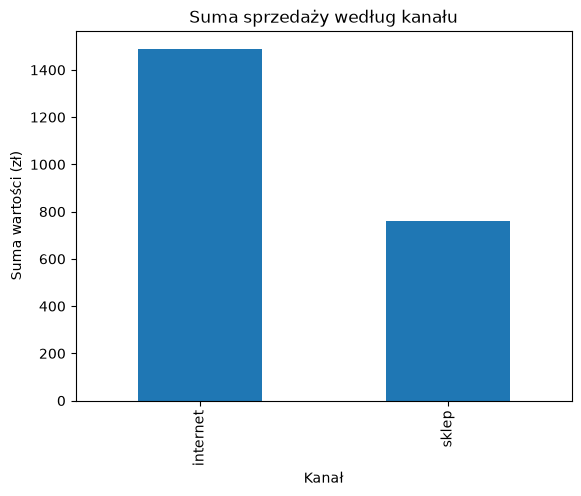

In [15]:
sprzedaz = df.groupby("kanal")["wartosc"].sum()
sprzedaz.plot(kind="bar")
plt.title("Suma sprzedaży według kanału")
plt.xlabel("Kanał")
plt.ylabel("Suma wartości (zł)")
plt.show()

Wnioski:
- Oba kanały mają po 6 zamówień, ale internet ma prawie dwa razy wyższą sumę sprzedaży (1490 zł a 760zł).
- Wynika to z wyższej średniej wartości zamówienia w internecie (ok. 248zł) niż w sklepie (ok. 127zł).